In [113]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [114]:
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')
Data = Data.iloc[:, 1:]

In [115]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [116]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   FPS                      10332 non-null  float64
 1   Frame Duration (ms)      10332 non-null  float64
 2   Min Frame Duration (ms)  10332 non-null  float64
 3   Max Frame Duration (ms)  10332 non-null  float64
 4   Avg Frame Duration (ms)  10332 non-null  float64
 5   Std Dev (ms)             10332 non-null  float64
 6   Entropy Framerate        10332 non-null  float64
 7   MotionToPhotonLatency    10332 non-null  float64
 8   minMtpLatency            10332 non-null  float64
 9   maxMtpLatency            10332 non-null  float64
 10  avgMtpLatency            10332 non-null  float64
 11  StdDev mtpLatency        10332 non-null  float64
 12  mtpEntropy               10332 non-null  float64
 13  currentRotation.x        10332 non-null  float64
 14  currentRotation.y     

In [117]:
Data.shape

(10332, 20)

In [118]:
# create new column "Labels" based on "FPS"
Data["Labels"] = Data["FPS"].apply(lambda x: 0 if x >= 60 else 1)

In [119]:
X = Data.iloc[:, :-1]
y = Data['Labels']

In [120]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [121]:
# Standardize the feature matrix
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X)

In [122]:
n_components=13
pca = PCA(n_components)
X_pca = pca.fit_transform(X_standardized)

In [123]:
# Calculate the cumulative explained variance ratio
cumulative_explained_variance = np.cumsum(pca.explained_variance_ratio_)

In [124]:
# Set the threshold for the cumulative explained variance (e.g., 95%)
threshold = 0.95

In [125]:
# Find the minimum number of components that meet the threshold
num_components = np.where(cumulative_explained_variance >= threshold)[0][0] + 1

In [126]:
print("Number of principal components to retain:", num_components)

Number of principal components to retain: 12


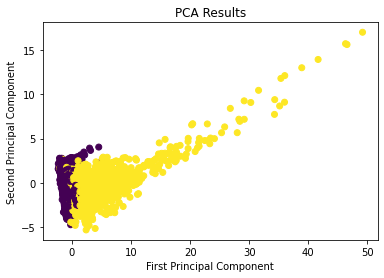

In [127]:
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA Results')
plt.show()

In [128]:
explained_variance_ratio = pca.explained_variance_ratio_
print("Explained Variance Ratio:", explained_variance_ratio)

Explained Variance Ratio: [0.42696004 0.13761162 0.07165356 0.05947045 0.05130321 0.04772548
 0.04596961 0.03317259 0.02676886 0.02499972 0.02224882 0.0142361
 0.01119369]


In [129]:
# Get the top features contributing to each principal component
num_principal_components = n_components
num_top_features = 5

In [130]:
feature_names = X.columns

In [131]:
for i in range(num_principal_components):
    top_features_component = np.argsort(np.abs(pca.components_[i]))[::-1][:num_top_features]
    print(f"Top features contributing to principal component {i + 1}:")
    print(feature_names[top_features_component])
    print()

Top features contributing to principal component 1:
Index(['Max Frame Duration (ms)', 'maxMtpLatency', 'Frame Duration (ms)',
       'MotionToPhotonLatency', 'Std Dev (ms)'],
      dtype='object')

Top features contributing to principal component 2:
Index(['currentRotation.y', 'yaw', 'Entropy Framerate', 'currentRotation.z',
       'currentRotation.x'],
      dtype='object')

Top features contributing to principal component 3:
Index(['pitch', 'currentRotation.x', 'roll', 'currentRotation.z',
       'currentRotation.y'],
      dtype='object')

Top features contributing to principal component 4:
Index(['mtpEntropy', 'Entropy Framerate', 'yaw', 'FPS', 'currentRotation.y'], dtype='object')

Top features contributing to principal component 5:
Index(['roll', 'currentRotation.x', 'currentRotation.z', 'pitch',
       'Entropy Framerate'],
      dtype='object')

Top features contributing to principal component 6:
Index(['currentRotation.w', 'pitch', 'yaw', 'currentRotation.z',
       'Avg Frame

In [132]:
top_features_per_component = []

In [133]:
for i in range(num_principal_components):
    top_features = np.argsort(np.abs(pca.components_[i]))[::-1][:num_top_features]
    top_features_per_component.append(top_features)

In [134]:
# Create a set to store unique top features from the first n principal components
unique_top_features = set()

In [135]:
# Create a set to store unique top features from the first n principal components
unique_top_features = set()

# Add the top features from each of the first n principal components to the set
for i in range(num_principal_components):
    unique_top_features.update(top_features_per_component[i])

print("Unique top features from the first 12 principal components:")
print(unique_top_features)

Unique top features from the first 12 principal components:
{0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19}


In [136]:
# Get the names of the unique top features
unique_top_feature_names = feature_names[list(unique_top_features)]

In [137]:
unique_top_feature_names 

Index(['FPS', 'Frame Duration (ms)', 'Min Frame Duration (ms)',
       'Max Frame Duration (ms)', 'Avg Frame Duration (ms)', 'Std Dev (ms)',
       'Entropy Framerate', 'MotionToPhotonLatency', 'minMtpLatency',
       'maxMtpLatency', 'avgMtpLatency', 'StdDev mtpLatency', 'mtpEntropy',
       'currentRotation.x', 'currentRotation.y', 'currentRotation.z',
       'currentRotation.w', 'pitch', 'yaw', 'roll'],
      dtype='object')